# Solución – Desafío: Clasificación con SVM: reconocimiento de dígitos manuscritos

**Objetivo:** construir un clasificador de Máquinas de Soporte Vectorial (SVM) que reconozca dígitos escritos a mano a partir de imágenes de 8×8 píxeles. Compararemos kernels, decidiremos con evidencia si conviene escalar, ajustaremos `C` y `gamma` con `GridSearchCV` y evaluaremos el modelo final con accuracy, reporte de clasificación y matriz de confusión.

**Dataset:** *Digits* (incluido en scikit-learn): 1.797 imágenes, 64 variables numéricas (intensidad de cada píxel, de 0 a 16) y 10 clases (dígitos del 0 al 9).

Versión resuelta, con resultados ejecutados.

## 1. Librerías

Usamos `pandas` para explorar, `matplotlib` para graficar y `scikit-learn` para el modelo, la validación y las métricas. La función `hallazgo()` imprime conclusiones calculadas a partir de los datos, de modo que se actualizan solas si los datos cambian.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

RANDOM_STATE = 42

def hallazgo(texto):
    print(f"🔎 Hallazgo: {texto}")

## 2. Carga de datos

Cada imagen de 8×8 se guarda como una fila de 64 columnas (`pixel_0_0` … `pixel_7_7`). La columna `digito` es la clase que queremos predecir.

In [2]:
datos = load_digits(as_frame=True)
df = datos.frame.rename(columns={"target": "digito"})
pixeles = datos.feature_names

# muestra las dimensiones del DataFrame y sus primeras 5 filas
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (1797, 65)


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,digito
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


Visualizamos un ejemplo de cada dígito para entender qué información reciben las variables.

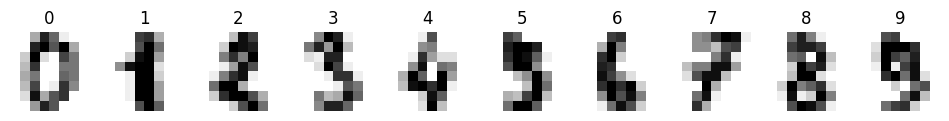

In [3]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for ax, d in zip(axes, range(10)):
    idx = df.index[df["digito"] == d][0]
    ax.imshow(datos.images[idx], cmap="gray_r")
    ax.set_title(str(d))
    ax.axis("off")
plt.show()

## 3. EDA mínimo necesario

Solo revisamos lo que influye en las decisiones del modelo:

1. **Valores nulos**: `SVC` de scikit-learn no acepta datos faltantes.
2. **Balance de clases**: define si estratificamos la partición y si el accuracy es una métrica informativa.
3. **Escala y variabilidad de las variables**: SVM mide distancias, así que la escala de cada variable afecta directamente la frontera.

### 3.1 Valores nulos

In [4]:
# cuenta el total de valores nulos del DataFrame
nulos = df.isnull().sum().sum()
hallazgo(f"el dataset tiene {nulos} valores nulos" + (": no se requiere imputación." if nulos == 0 else ": hay que imputar antes de entrenar."))

🔎 Hallazgo: el dataset tiene 0 valores nulos: no se requiere imputación.


### 3.2 Balance de clases

        casos  proporción
digito                   
0         178       0.099
1         182       0.101
2         177       0.098
3         183       0.102
4         181       0.101
5         182       0.101
6         181       0.101
7         179       0.100
8         174       0.097
9         180       0.100


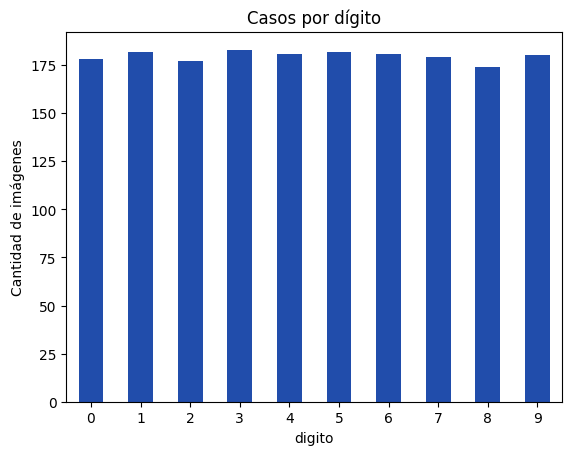

🔎 Hallazgo: la clase menos frecuente tiene 174 casos y la más frecuente 183 (razón 0.95): las clases están equilibradas, así que el accuracy es informativo; igual estratificaremos para que entrenamiento y prueba conserven las mismas proporciones.


In [5]:
# calcula el conteo y la proporción de cada dígito, ordenados por dígito
conteo = df["digito"].value_counts().sort_index()
proporcion = df["digito"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"casos": conteo, "proporción": proporcion.round(3)}))

conteo.plot(kind="bar", color="#214DAB", rot=0, title="Casos por dígito")
plt.ylabel("Cantidad de imágenes")
plt.show()

razon = conteo.min() / conteo.max()
hallazgo(f"la clase menos frecuente tiene {conteo.min()} casos y la más frecuente {conteo.max()} (razón {razon:.2f}): "
         + ("las clases están equilibradas, así que el accuracy es informativo; igual estratificaremos "
            "para que entrenamiento y prueba conserven las mismas proporciones." if razon > 0.8
            else "hay desbalance: estratificaremos y miraremos métricas por clase."))

### 3.3 Escala y variabilidad de los píxeles

SVM construye la frontera midiendo distancias entre casos. Revisamos si las variables están en la misma escala y cuánto varía cada píxel. El mapa de calor muestra la desviación estándar de cada píxel ubicada en su posición dentro de la imagen.

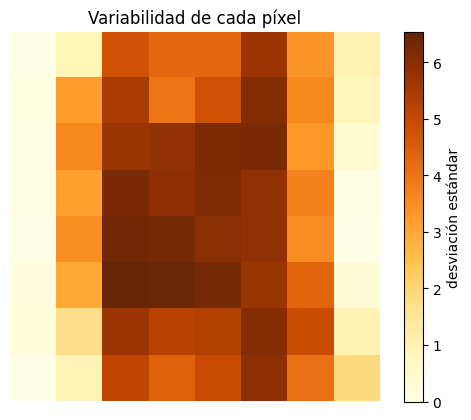

🔎 Hallazgo: todos los píxeles comparten la misma escala (0 a 16), pero su desviación estándar va de 0.00 a 6.54; 3 píxeles son constantes y 16 tienen desviación menor que 1 (sobre todo en los bordes).
🔎 Hallazgo: StandardScaler daría a todos los píxeles el mismo peso, incluidos los de borde casi constantes. No asumiremos que escalar ayuda: lo comprobaremos con validación cruzada en la sección 7.


In [6]:
# calcula la desviación estándar de cada píxel
desv = df[pixeles].std()

minimo, maximo = df[pixeles].values.min(), df[pixeles].values.max()
constantes = (desv == 0).sum()
casi_constantes = (desv < 1).sum()

plt.imshow(desv.values.reshape(8, 8), cmap="YlOrBr")
plt.colorbar(label="desviación estándar")
plt.title("Variabilidad de cada píxel")
plt.axis("off")
plt.show()

hallazgo(f"todos los píxeles comparten la misma escala ({minimo:.0f} a {maximo:.0f}), pero su desviación estándar va de "
         f"{desv.min():.2f} a {desv.max():.2f}; {constantes} píxeles son constantes y {casi_constantes} tienen desviación menor que 1 "
         "(sobre todo en los bordes).")
hallazgo("StandardScaler daría a todos los píxeles el mismo peso, incluidos los de borde casi constantes. "
         "No asumiremos que escalar ayuda: lo comprobaremos con validación cruzada en la sección 7.")

## 4. Partición entrenamiento / prueba

Separamos 80% para entrenar y 20% para la evaluación final. Usamos `stratify=y` para que ambas particiones conserven la proporción de cada dígito.

El conjunto de prueba **no se usa** para comparar modelos ni elegir hiperparámetros: todas esas decisiones se toman con validación cruzada sobre entrenamiento. La prueba se usa una sola vez, en la sección 9.

In [7]:
X = df[pixeles]
y = df["digito"]

# separa 20% para prueba, con random_state=RANDOM_STATE y estratificando por y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (1437, 64) | Prueba: (360, 64)


## 5. Punto de partida: SVM lineal

Vamos de lo simple a lo complejo: primero un kernel lineal, el más rápido y fácil de interpretar. Usamos un `Pipeline` para que el escalado se ajuste solo con los datos de cada fold de entrenamiento y no haya fuga de información.

Evaluamos con validación cruzada de 5 folds sobre entrenamiento: obtenemos el accuracy medio y su desviación estándar entre folds.

In [8]:
resultados = {}

# arma un Pipeline con un paso "scaler" (StandardScaler) y un paso "svc" (SVC con kernel lineal)
svm_lineal = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear"))
])

# evalúa el pipeline con validación cruzada de 5 folds sobre los datos de entrenamiento
cv_lineal = cross_val_score(svm_lineal, X_train, y_train, cv=5)
resultados["Lineal + escalado"] = cv_lineal
print(f"SVM lineal - accuracy CV: {cv_lineal.mean():.4f} ± {cv_lineal.std():.4f}")

SVM lineal - accuracy CV: 0.9756 ± 0.0079


## 6. Frontera no lineal: kernel RBF

El kernel RBF permite fronteras curvas. Partimos con `C=10` y `gamma="scale"` (valor que scikit-learn calcula a partir de la varianza de los datos).

In [9]:
# arma el mismo Pipeline, pero con un SVC de kernel "rbf", C=10 y gamma="scale"
svm_rbf = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale"))
])

cv_rbf = cross_val_score(svm_rbf, X_train, y_train, cv=5)
resultados["RBF + escalado"] = cv_rbf
print(f"SVM RBF - accuracy CV: {cv_rbf.mean():.4f} ± {cv_rbf.std():.4f}")

dif = cv_rbf.mean() - cv_lineal.mean()
hallazgo(f"el kernel RBF {'supera' if dif > 0 else 'no supera'} al lineal por {abs(dif) * 100:.2f} puntos porcentuales: "
         + ("la frontera entre dígitos se beneficia de la flexibilidad del kernel no lineal." if dif > 0
            else "una frontera lineal es suficiente para este problema."))

SVM RBF - accuracy CV: 0.9833 ± 0.0068
🔎 Hallazgo: el kernel RBF supera al lineal por 0.77 puntos porcentuales: la frontera entre dígitos se beneficia de la flexibilidad del kernel no lineal.


## 7. ¿Escalar o no escalar?

La regla general dice que SVM requiere escalar, pero el EDA mostró que aquí todos los píxeles ya comparten la misma unidad. Comprobamos con evidencia: repetimos el modelo RBF reemplazando el escalador por `"passthrough"`, que deja pasar los datos sin transformarlos.

SVM RBF sin escalar - accuracy CV: 0.9889 ± 0.0056


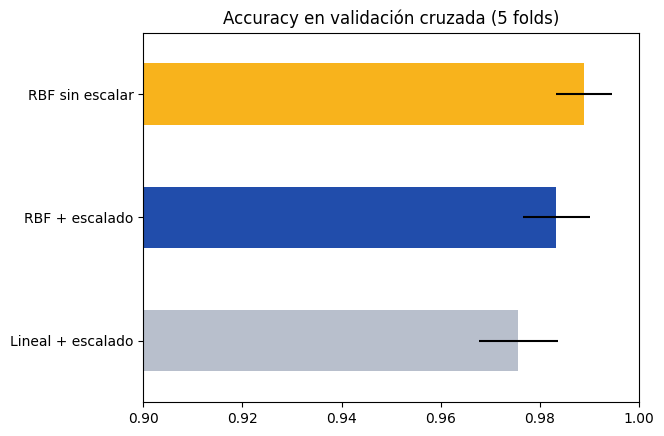

🔎 Hallazgo: NO escalar mejora el accuracy en 0.56 puntos porcentuales (una diferencia menor que la variabilidad entre folds). Coherente con el EDA: los píxeles ya comparten unidad y estandarizar amplifica los píxeles de borde casi constantes.
Configuración elegida: sin escalado


In [10]:
# arma el Pipeline RBF sin escalado, usando "passthrough" en el paso "scaler"
svm_rbf_sin = Pipeline(steps=[
    ("scaler", "passthrough"),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale"))
])

cv_rbf_sin = cross_val_score(svm_rbf_sin, X_train, y_train, cv=5)
resultados["RBF sin escalar"] = cv_rbf_sin
print(f"SVM RBF sin escalar - accuracy CV: {cv_rbf_sin.mean():.4f} ± {cv_rbf_sin.std():.4f}")

resumen = pd.DataFrame({k: [v.mean(), v.std()] for k, v in resultados.items()}, index=["media", "desv"]).T
resumen["media"].plot(kind="barh", xerr=resumen["desv"], color=["#B8BFCC", "#214DAB", "#F8B31C"], xlim=(0.9, 1.0),
                      title="Accuracy en validación cruzada (5 folds)")
plt.show()

usar_escalado = cv_rbf.mean() >= cv_rbf_sin.mean()
dif = abs(cv_rbf.mean() - cv_rbf_sin.mean())
hallazgo(f"{'escalar mejora' if usar_escalado else 'NO escalar mejora'} el accuracy en {dif * 100:.2f} puntos porcentuales "
         + ("(una diferencia menor que la variabilidad entre folds)." if dif < max(cv_rbf.std(), cv_rbf_sin.std())
            else "(una diferencia mayor que la variabilidad entre folds).")
         + ("" if usar_escalado else " Coherente con el EDA: los píxeles ya comparten unidad y estandarizar "
            "amplifica los píxeles de borde casi constantes."))
escalador = StandardScaler() if usar_escalado else "passthrough"
print("Configuración elegida:", "con escalado" if usar_escalado else "sin escalado")

## 8. Ajuste de hiperparámetros con GridSearchCV

Buscamos la mejor combinación de `C` y `gamma` probando todas las combinaciones de una grilla, cada una evaluada con validación cruzada sobre entrenamiento.

El valor útil de `gamma` depende de la escala de los datos. Por eso la grilla se construye alrededor de un **gamma de referencia**, el mismo que calcula `gamma="scale"`: 1 / (n.º de variables × varianza de los datos), multiplicado por 0,1; 1 y 10. `C` se explora en escala logarítmica.

Recuerda: dentro de un `Pipeline`, cada parámetro se nombra como `paso__parámetro` (por ejemplo, `svc__C`).

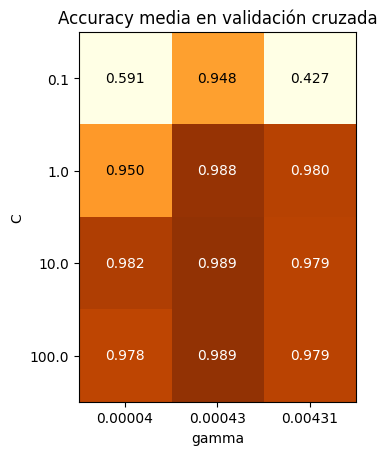

🔎 Hallazgo: la mejor combinación es C = 10 y gamma = 0.00043, con accuracy CV de 0.9889.
🔎 Hallazgo: el óptimo está en el interior de la grilla: el rango explorado es adecuado.
🔎 Hallazgo: el modelo usa 570 vectores soporte, el 39.7% de los casos de entrenamiento; el resto no influye en la frontera.


In [11]:
X_ref = StandardScaler().fit_transform(X_train) if usar_escalado else X_train.values
gamma_ref = 1 / (X_ref.shape[1] * X_ref.var())

grilla = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": list(gamma_ref * np.array([0.1, 1, 10]))
}

# arma el Pipeline RBF usando el escalador elegido en la sección 7
pipe = Pipeline(steps=[
    ("scaler", escalador),
    ("svc", SVC(kernel="rbf"))
])

# crea un GridSearchCV con el pipeline, la grilla y 5 folds, y entrénalo con los datos de entrenamiento
busqueda = GridSearchCV(pipe, grilla, cv=5)
busqueda.fit(X_train, y_train)

tabla = pd.DataFrame(busqueda.cv_results_["mean_test_score"].reshape(len(grilla["svc__C"]), len(grilla["svc__gamma"])),
                     index=grilla["svc__C"], columns=[f"{g:.5f}" for g in grilla["svc__gamma"]])
plt.imshow(tabla.values, cmap="YlOrBr", vmin=0.9, vmax=1)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.values[i, j]
        plt.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v > 0.97 else "black")
plt.xticks(range(tabla.shape[1]), tabla.columns); plt.yticks(range(tabla.shape[0]), tabla.index)
plt.xlabel("gamma"); plt.ylabel("C"); plt.title("Accuracy media en validación cruzada")
plt.show()

mejor_C, mejor_gamma = busqueda.best_params_["svc__C"], busqueda.best_params_["svc__gamma"]
hallazgo(f"la mejor combinación es C = {mejor_C} y gamma = {mejor_gamma:.5f}, con accuracy CV de {busqueda.best_score_:.4f}.")
if mejor_C in (min(grilla["svc__C"]), max(grilla["svc__C"])) or mejor_gamma in (min(grilla["svc__gamma"]), max(grilla["svc__gamma"])):
    hallazgo("el óptimo está en el borde de la grilla: convendría ampliarla en esa dirección.")
else:
    hallazgo("el óptimo está en el interior de la grilla: el rango explorado es adecuado.")

modelo_final = busqueda.best_estimator_
n_sv = modelo_final.named_steps["svc"].n_support_.sum()
hallazgo(f"el modelo usa {n_sv} vectores soporte, el {n_sv / len(X_train):.1%} de los casos de entrenamiento; "
         "el resto no influye en la frontera.")

## 9. Evaluación final en prueba

Recién ahora usamos el conjunto de prueba, una sola vez, con el modelo elegido.

### 9.1 Accuracy
Lo comparamos con el accuracy de validación cruzada y con un clasificador trivial que siempre predice la clase más frecuente.

In [12]:
# predice las clases del conjunto de prueba y calcula el accuracy
y_pred = modelo_final.predict(X_test)
acc = accuracy_score(y_test, y_pred)
acc_trivial = (y_test == y_train.mode()[0]).mean()

print(f"Accuracy SVM (prueba):       {acc:.4f}")
print(f"Accuracy CV (entrenamiento): {busqueda.best_score_:.4f}")
print(f"Accuracy clase mayoritaria:  {acc_trivial:.4f}")
hallazgo(f"el accuracy en prueba difiere en {abs(acc - busqueda.best_score_) * 100:.2f} puntos del estimado por validación cruzada "
         f"y supera al clasificador trivial por {(acc - acc_trivial) * 100:.1f} puntos.")

Accuracy SVM (prueba):       0.9944
Accuracy CV (entrenamiento): 0.9889
Accuracy clase mayoritaria:  0.1000
🔎 Hallazgo: el accuracy en prueba difiere en 0.56 puntos del estimado por validación cruzada y supera al clasificador trivial por 89.4 puntos.


### 9.2 Reporte de clasificación
Aunque las clases están equilibradas, el reporte muestra si algún dígito específico es más difícil de reconocer.

In [13]:
# imprime el reporte de clasificación con 3 decimales
print(classification_report(y_test, y_pred, digits=3))

reporte = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).T.iloc[:10]
peor = reporte["recall"].idxmin()
hallazgo(f"el dígito con menor recall es el {peor} ({reporte.loc[peor, 'recall']:.3f}); "
         f"el recall promedio es {reporte['recall'].mean():.3f}.")

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.973     1.000     0.986        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     1.000     1.000        36
           7      0.973     1.000     0.986        36
           8      1.000     0.971     0.986        35
           9      1.000     0.972     0.986        36

    accuracy                          0.994       360
   macro avg      0.995     0.994     0.994       360
weighted avg      0.995     0.994     0.994       360

🔎 Hallazgo: el dígito con menor recall es el 8 (0.971); el recall promedio es 0.994.


### 9.3 Matriz de confusión
Muestra qué dígitos confunde el modelo entre sí.

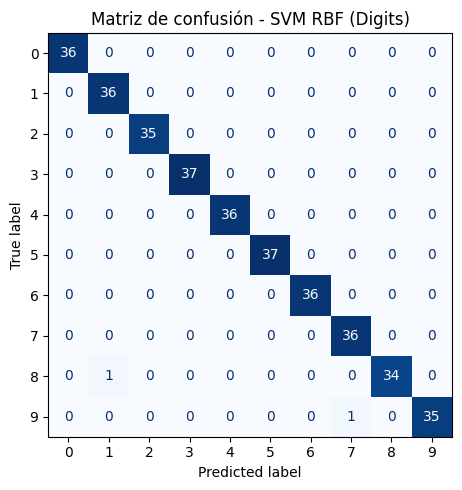

🔎 Hallazgo: el modelo cometió 2 errores en 360 imágenes; la confusión más frecuente es un 8 clasificado como 1 (1 caso).


In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
# grafica la matriz de confusión a partir de y_test e y_pred
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de confusión - SVM RBF (Digits)")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred)
errores = cm.sum() - np.trace(cm)
np.fill_diagonal(cm, 0)
if errores == 0:
    hallazgo("el modelo no cometió errores en prueba.")
else:
    real, pred = np.unravel_index(cm.argmax(), cm.shape)
    hallazgo(f"el modelo cometió {errores} errores en {len(y_test)} imágenes; la confusión más frecuente es "
             f"un {real} clasificado como {pred} ({cm[real, pred]} caso{'s' if cm[real, pred] > 1 else ''}).")

### 9.4 Imágenes mal clasificadas
Mirar los errores ayuda a juzgar si son razonables o revelan un problema del modelo.

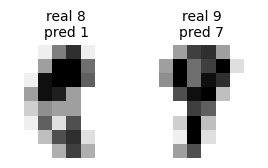

In [15]:
mal = np.where(y_pred != y_test.values)[0][:8]
if len(mal) > 0:
    fig, axes = plt.subplots(1, len(mal), figsize=(1.6 * len(mal), 2))
    for ax, i in zip(np.atleast_1d(axes), mal):
        ax.imshow(X_test.iloc[i].values.reshape(8, 8), cmap="gray_r")
        ax.set_title(f"real {y_test.iloc[i]}\npred {y_pred[i]}", fontsize=10)
        ax.axis("off")
    plt.show()

## 10. Preguntas de cierre

Responde en esta celda, apoyándote en los hallazgos que obtuviste:

1. ¿Qué kernel obtuvo mejor accuracy en validación cruzada? ¿Qué sugiere eso sobre la forma de la frontera entre los dígitos?
2. ¿Ayudó el escalado en este dataset? Relaciona tu respuesta con el EDA de la sección 3.3. ¿Significa esto que la regla "SVM requiere escalar" es incorrecta?
3. ¿Por qué elegimos los hiperparámetros con validación cruzada y no con el conjunto de prueba?
4. ¿Qué porcentaje de los casos de entrenamiento quedaron como vectores soporte? ¿Qué significa eso para el modelo?
5. ¿Qué par de dígitos confunde más el modelo? Observando las imágenes mal clasificadas, ¿el error es comprensible?



### Pauta de respuestas

Las respuestas se calculan a partir de los resultados del notebook, de modo que siguen siendo válidas si los datos o la partición cambian.

In [16]:
def respuesta(n, texto):
    print(f"P{n}. {texto}\n")

# 1. Kernel
mejor_kernel = "RBF" if cv_rbf.mean() > cv_lineal.mean() else "lineal"
dif_k = abs(cv_rbf.mean() - cv_lineal.mean())
respuesta(1, f"El kernel {mejor_kernel} obtuvo el mejor accuracy en validación cruzada ({max(cv_rbf.mean(), cv_lineal.mean()):.4f} "
             f"vs {min(cv_rbf.mean(), cv_lineal.mean()):.4f}, diferencia de {dif_k * 100:.2f} puntos). "
             f"Que el kernel lineal ya alcance {cv_lineal.mean():.1%} indica que, en 64 dimensiones, los dígitos son casi "
             "linealmente separables: en alta dimensión es más fácil separar clases con un hiperplano. "
             + ("El RBF agrega flexibilidad para los casos cercanos a la frontera, donde las clases se curvan o se mezclan, "
                "y eso explica la mejora." if mejor_kernel == "RBF"
                else "La flexibilidad extra del RBF no aporta: la frontera lineal es suficiente."))

# 2. Escalado
dif_e = abs(cv_rbf.mean() - cv_rbf_sin.mean())
dentro_ruido = dif_e < max(cv_rbf.std(), cv_rbf_sin.std())
regla = ("La regla 'SVM requiere escalar' no es incorrecta: es correcta cuando las variables están en unidades o rangos "
         "distintos, que es el caso habitual. Lo que muestra este dataset es que el escalado es una decisión de "
         "preprocesamiento que se valida con evidencia, no un paso automático.")
if not usar_escalado:
    respuesta(2, f"No: sin escalar el accuracy fue {dif_e * 100:.2f} puntos mayor"
                 + (", una diferencia menor que la variabilidad entre folds, así que escalar no aporta nada. " if dentro_ruido else ". ")
                 + f"El EDA de la sección 3.3 lo anticipaba: todos los píxeles miden lo mismo (intensidad de {minimo:.0f} a "
                 f"{maximo:.0f}), así que ninguno domina la distancia por su unidad. Además, {casi_constantes} píxeles de borde "
                 "casi no varían; StandardScaler los lleva a desviación 1 y amplifica su ruido. " + regla)
else:
    respuesta(2, f"Sí: escalar mejoró el accuracy en {dif_e * 100:.2f} puntos"
                 + (", aunque la diferencia es menor que la variabilidad entre folds. " if dentro_ruido else ". ")
                 + "Aunque los píxeles comparten unidad, igualar su variabilidad favoreció a este modelo. " + regla)

# 3. Validación cruzada vs prueba
respuesta(3, "Si elegimos C y gamma según el conjunto de prueba, la prueba pasa a ser parte del entrenamiento: los "
             "hiperparámetros quedan ajustados a esos 360 casos y el accuracy reportado sería optimista (fuga de información). "
             f"La validación cruzada elige con datos de entrenamiento ({busqueda.best_score_:.4f}) y deja la prueba intacta "
             f"para una única estimación honesta del desempeño con datos nuevos ({acc:.4f}).")

# 4. Vectores soporte
pct_sv = n_sv / len(X_train)
respuesta(4, f"Quedaron {n_sv} vectores soporte, el {pct_sv:.1%} de los {len(X_train)} casos de entrenamiento. "
             "Solo esos casos definen la frontera: el resto podría eliminarse sin cambiar el modelo, y el costo de predecir "
             "crece con su número. "
             + ("Un porcentaje alto indica muchos casos cerca o dentro de la calle: fronteras complejas o clases que se "
                "superponen. " if pct_sv > 0.3 else "Un porcentaje bajo indica clases bien separadas. ")
             + "Hay que considerar que SVC usa uno contra uno (45 SVM binarias) y un caso cuenta como vector soporte "
             "si lo es en al menos uno de esos modelos.")

# 5. Confusiones
if errores == 0:
    respuesta(5, "El modelo no cometió errores en prueba, así que no hay pares confundidos que analizar.")
else:
    respuesta(5, f"La confusión más frecuente fue un {real} clasificado como {pred} ({cm[real, pred]} "
                 f"caso{'s' if cm[real, pred] > 1 else ''}), dentro de {errores} errores en {len(y_test)} imágenes. "
                 + ("Con tan pocos errores no hay un patrón sistemático: son casos aislados. " if errores <= 5
                    else "Si el mismo par se repite, hay un patrón que conviene revisar. ")
                 + "Las imágenes de la sección 9.4 "
                 "ayudan a juzgarlo: con una resolución de 8×8 píxeles, un trazo débil o incompleto basta para que un "
                 "dígito se parezca a otro, y muchas de esas imágenes son ambiguas incluso para una persona. "
                 "Errores comprensibles sugieren que el límite está en la calidad de los datos más que en el modelo.")

P1. El kernel RBF obtuvo el mejor accuracy en validación cruzada (0.9833 vs 0.9756, diferencia de 0.77 puntos). Que el kernel lineal ya alcance 97.6% indica que, en 64 dimensiones, los dígitos son casi linealmente separables: en alta dimensión es más fácil separar clases con un hiperplano. El RBF agrega flexibilidad para los casos cercanos a la frontera, donde las clases se curvan o se mezclan, y eso explica la mejora.

P2. No: sin escalar el accuracy fue 0.56 puntos mayor, una diferencia menor que la variabilidad entre folds, así que escalar no aporta nada. El EDA de la sección 3.3 lo anticipaba: todos los píxeles miden lo mismo (intensidad de 0 a 16), así que ninguno domina la distancia por su unidad. Además, 16 píxeles de borde casi no varían; StandardScaler los lleva a desviación 1 y amplifica su ruido. La regla 'SVM requiere escalar' no es incorrecta: es correcta cuando las variables están en unidades o rangos distintos, que es el caso habitual. Lo que muestra este dataset es que 